# Resultados del entregable: plantas existentes, plantas a suministrar y probabilidades de transición

Este notebook **no vuelve a optimizar nada**. Lee las salidas de `modelo_compra_acoplado_v6.ipynb` y los datos de entrada, y presenta:

1. Valor esperado del total de plantas existentes en una hectárea.
2. Valor esperado de plantas por especie existentes en una hectárea.
3. Valor esperado de plantas por especie a suministrar por hectárea.
4. Probabilidad de transición entre plantas (cada planta es un estado).
5. Valor esperado de competencia existente en una hectárea


**Archivos que usa**

| Archivo | Origen | Para qué |
|---|---|---|
| `datos_limpios.csv`, `parametros_especies.csv` | datos de entrada | inventario de plantas existentes, áreas, metas y supervivencia |
| `plan_compra_equilibrado.csv` | salida de v6 (sección 4, con el remanente reasignado) | siembras y reposiciones compradas por polígono y especie |
| `plantilla_plan.csv`, `plantillas_poligono.csv` | salidas de v6 (secciones 5.1–5.4, plantillas de 14 × 47 con el castigo por agrupamiento) | orden de las especies en la plantilla |

**Simulación.** Se hacen 1,000 simulaciones del proceso de siembra con el mismo modelo de v6: plantas existentes $X_{e,p}\sim\text{Bin}(x_{e,p},0.95)$ (5 % de error de registro), siembras establecidas $Z^I_{e,p}\sim\text{Bin}(q^I_{e,p},S_e)$, reposición de hasta $q^R_{e,p}$ plantas muertas y reposiciones establecidas $Z^R_{e,p}\sim\text{Bin}(\min\{q^R_{e,p},q^I_{e,p}-Z^I_{e,p}\},S_e)$, con $S_e$ la supervivencia de 2023.

**"Por hectárea".** Para el predio se divide el total entre el área total (183 ha), que es el promedio ponderado por área de los 30 polígonos. Como el bloque de 14 × 47 tiene 658 posiciones, una plantilla equivale exactamente a una hectárea.

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N_SIM, SEED = 1000, 2026
ERR_REG = 0.05
SUPERV  = 'sobrev_2023'
ESC     = 'B'                                    # escenario de compra que se reporta (A, B o C)

DATOS   = 'datos/especies y poligonos/'
SALIDAS = 'salidas/'
PLAN    = 'plan_compra_equilibrado.csv' if os.path.exists('plan_compra_equilibrado.csv') else SALIDAS + 'plan_compra_equilibrado.csv'

datos = pd.read_csv(DATOS + 'datos_limpios.csv')
par   = pd.read_csv(DATOS + 'parametros_especies.csv').set_index('especie')
plan  = pd.read_csv(PLAN)
esp   = list(par.index); E_ = len(esp)
x     = datos.pivot(index='especie', columns='poligono', values='plantas').loc[esp]
A     = datos.drop_duplicates('poligono').set_index('poligono')['area_ha'].sort_index()
x     = x[A.index]; P_ = len(A)
d, c, S = (par[k].values.astype(float) for k in ('meta_plantas_ha', 'costo_c', SUPERV))
D = np.outer(d, A.values)

q  = plan[plan.escenario == ESC]
QI = q.pivot(index='especie', columns='poligono', values='q_siembra').loc[esp, A.index].values
QR = q.pivot(index='especie', columns='poligono', values='q_reposicion').loc[esp, A.index].values
assert set(q.poligono) == set(A.index) and (QR <= QI).all()

PALETA = ['#8fc80c', '#00dc7f', '#0073ac', '#ffed49', '#10b509', '#6f44eb', '#37ffd6', '#00ac98', '#ffa730', '#ff5cab']
corto = [e.split()[0][0] + '. ' + e.split()[1] for e in esp]                 # A. lechuguilla, ...
print(f'{P_} polígonos, {A.sum():.2f} ha | escenario {ESC}: {QI.sum():,} siembras + {QR.sum():,} reposiciones compradas')

30 polígonos, 183.01 ha | escenario B: 98,017 siembras + 4,551 reposiciones compradas


In [5]:
# ---------- 1,000 simulaciones del proceso de siembra ----------
r  = np.random.default_rng(SEED)
X  = r.binomial(x.values, 1 - ERR_REG, size=(N_SIM, E_, P_))               # plantas existentes
ZI = r.binomial(QI, S[:, None], size=(N_SIM, E_, P_))                      # siembras establecidas a 2 años
R  = np.minimum(QR, QI - ZI)                                                # reposiciones que sí se usan
ZR = r.binomial(R, S[:, None])                                              # reposiciones establecidas
VIVAS = X + ZI + ZR                                                         # plantas vivas a los 2 años
area = A.sum()

def resumen_ha(tot):
    # tot: (N_SIM,) total del predio en cada simulación -> media, IC 95 % de la media y percentiles 5-95, por hectárea
    v = tot / area; m = v.mean(); se = v.std(ddof=1) / np.sqrt(len(v))
    return pd.Series({'media': m, 'IC95_media_inf': m - 1.96 * se, 'IC95_media_sup': m + 1.96 * se,
                      'P5': np.percentile(v, 5), 'P95': np.percentile(v, 95)})

## 1. Total de plantas existentes por hectárea

Se reportan dos momentos:

- **Antes de sembrar**: el inventario corregido por el error de registro. Su valor esperado también se puede calcular de forma exacta, $\mathbb{E}[X]=0.95\,x$, y sirve para comprobar la simulación.
- **A los dos años**: existentes más siembras y reposiciones que se establecieron. Se compara con la meta de 658 plantas/ha.

El intervalo de confianza es el de la media (qué tan precisa es la estimación con 1,000 simulaciones); los percentiles 5–95 muestran cuánto puede variar el resultado real.

,media,IC95_media_inf,IC95_media_sup,P5,P95,exacto (sin simular),meta
Existentes antes de sembrar,122.4,122.3,122.4,122.1,122.7,122.3,658.0
Vivas a los 2 años (existentes + establecidas),604.8,604.7,604.8,603.8,605.8,NaN,658.0


Existentes por ha entre polígonos: mín 116.1 (polígono 18), máx 131.8 (polígono 24)
Vivas a 2 años por ha entre polígonos: mín 599.3, máx 617.3


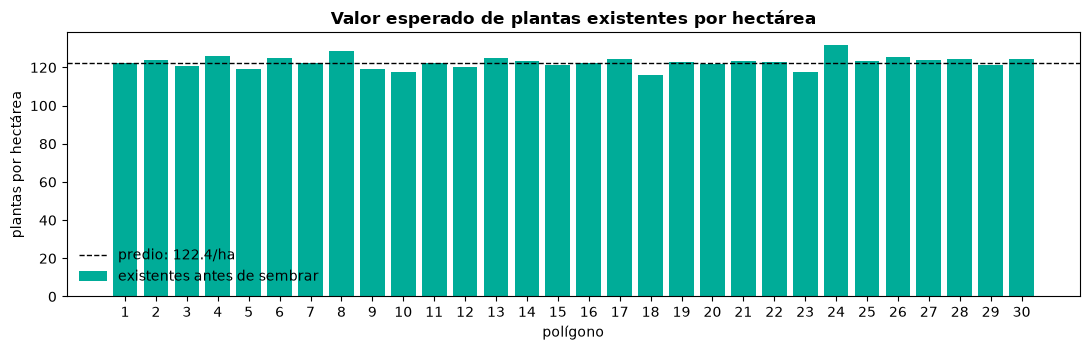

In [6]:
t1 = pd.DataFrame({
    'Existentes antes de sembrar': resumen_ha(X.sum((1, 2))),
    'Vivas a los 2 años (existentes + establecidas)': resumen_ha(VIVAS.sum((1, 2))),
}).T
t1['exacto (sin simular)'] = [0.95 * x.values.sum() / area, np.nan]
t1['meta'] = d.sum()
display(t1.round(1))

pol = pd.DataFrame({'area_ha': A, 'existentes_ha': X.mean(0).sum(0) / A.values,
                    'vivas_2_anios_ha': VIVAS.mean(0).sum(0) / A.values}, index=A.index)
print(f'Existentes por ha entre polígonos: mín {pol.existentes_ha.min():.1f} (polígono {pol.existentes_ha.idxmin()}), '
      f'máx {pol.existentes_ha.max():.1f} (polígono {pol.existentes_ha.idxmax()})')
print(f'Vivas a 2 años por ha entre polígonos: mín {pol.vivas_2_anios_ha.min():.1f}, máx {pol.vivas_2_anios_ha.max():.1f}')

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(pol.index.astype(str), pol.existentes_ha, color='#00ac98', label='existentes antes de sembrar')
ax.axhline(t1.iloc[0]['media'], color='k', lw=1, ls='--', label=f"predio: {t1.iloc[0]['media']:.1f}/ha")
ax.set_xlabel('polígono'); ax.set_ylabel('plantas por hectárea'); ax.legend(frameon=False)
ax.set_title('Valor esperado de plantas existentes por hectárea', fontweight='bold'); plt.tight_layout(); plt.show()

## 2. Plantas existentes por especie por hectárea

Para cada especie: el valor esperado en el predio, el rango entre polígonos y qué fracción de la meta ya está cubierta por las plantas existentes. La columna "vivas a 2 años" incluye lo que se siembra y se repone.

,meta_ha,existentes_ha,P5,P95,min_poligono,max_poligono,existentes_%_de_meta,vivas_2_anios_ha,vivas_%_de_meta
Agave lechuguilla,42.0,7.7,7.7,7.8,4.8,10.0,18.4,38.6,92.0
Agave salmiana,196.0,36.1,35.9,36.3,32.5,42.4,18.4,180.0,91.8
Agave scabra,42.0,7.6,7.5,7.7,6.0,11.9,18.1,38.6,92.0
Agave striata,42.0,7.3,7.2,7.4,5.3,11.9,17.4,38.6,92.0
Opuntia cantabrigiensis,49.0,9.5,9.4,9.6,7.6,12.4,19.4,45.1,92.0
Opuntia engelmannii,38.0,7.6,7.5,7.6,6.2,11.6,19.9,35.0,92.0
Opuntia robusta,73.0,14.3,14.2,14.4,11.0,16.0,19.5,67.1,91.9
Opuntia streptacantha,64.0,11.9,11.8,12.0,6.5,14.3,18.6,58.8,91.9
Prosopis laevigata,86.0,15.7,15.6,15.8,11.1,25.2,18.2,79.0,91.9
Yucca filifera,26.0,4.7,4.7,4.8,3.0,7.6,18.2,23.9,92.0


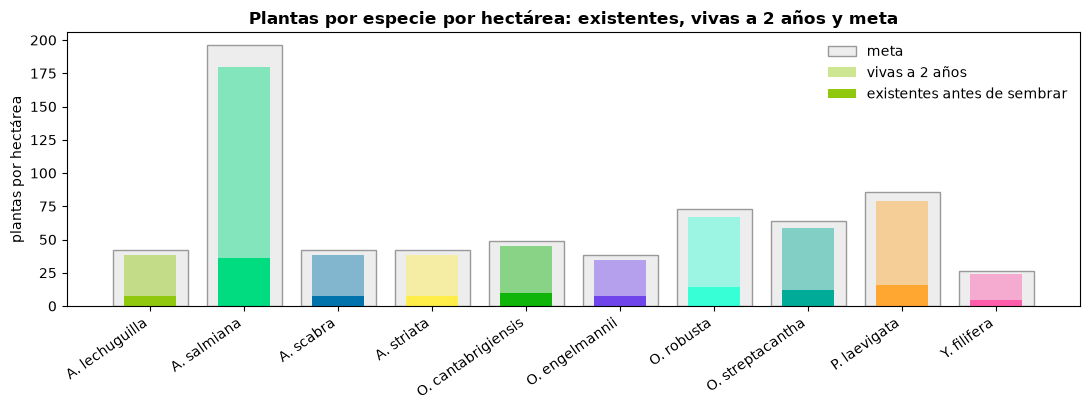

In [7]:
ex_e = X.sum(2) / area                                                     # (N_SIM, E): existentes/ha del predio
vv_e = VIVAS.sum(2) / area
pol_e = X.mean(0) / A.values                                                # (E, P): existentes/ha por polígono
t2 = pd.DataFrame({'meta_ha': d,
                   'existentes_ha': ex_e.mean(0),
                   'P5': np.percentile(ex_e, 5, axis=0), 'P95': np.percentile(ex_e, 95, axis=0),
                   'min_poligono': pol_e.min(1), 'max_poligono': pol_e.max(1),
                   'existentes_%_de_meta': 100 * ex_e.mean(0) / d,
                   'vivas_2_anios_ha': vv_e.mean(0),
                   'vivas_%_de_meta': 100 * vv_e.mean(0) / d}, index=esp)
t2.loc['Total'] = t2.sum(); t2.loc['Total', ['P5', 'P95', 'min_poligono', 'max_poligono']] = np.nan
t2.loc['Total', 'existentes_%_de_meta'] = 100 * t2.loc['Total', 'existentes_ha'] / d.sum()
t2.loc['Total', 'vivas_%_de_meta'] = 100 * t2.loc['Total', 'vivas_2_anios_ha'] / d.sum()
display(t2.round(1))

fig, ax = plt.subplots(figsize=(11, 4.2)); i = np.arange(E_)
ax.bar(i, d, color='#ededed', edgecolor='#999999', label='meta')
ax.bar(i, t2.vivas_2_anios_ha[:E_], 0.55, color=PALETA, alpha=0.45, label='vivas a 2 años')
ax.bar(i, t2.existentes_ha[:E_], 0.55, color=PALETA, label='existentes antes de sembrar')
ax.set_xticks(i, corto, rotation=35, ha='right'); ax.set_ylabel('plantas por hectárea')
ax.set_title('Plantas por especie por hectárea: existentes, vivas a 2 años y meta', fontweight='bold')
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 3. Plantas por especie a suministrar por hectárea

- **Siembra** $q^I$ y **reposición comprada** $q^R$ vienen del plan de compra (son decisiones, no aleatorias).
- **Reposición usada**: solo se repone lo que muere, hasta lo comprado, así que en promedio se usan menos reposiciones de las compradas. Su valor esperado sale de la simulación.
- **Plantas a suministrar (esperado)** = siembra + reposición usada. Es la cantidad que el vivero tendría que entregar en promedio; la diferencia con lo comprado es el margen que conviene tener disponible.
- El costo por hectárea usa el precio por planta de `parametros_especies.csv`.

,siembra_ha,reposicion_comprada_ha,reposicion_usada_ha_E,reposicion_usada_P95,suministrar_ha_E,comprado_ha,costo_comprado_ha,costo_suministrado_ha_E
Agave lechuguilla,32.47,0.87,0.86,0.87,33.34,33.34,866.90,866.78
Agave salmiana,154.20,4.23,4.23,4.23,158.43,158.43,4119.28,4119.28
Agave scabra,36.39,5.26,5.25,5.26,41.64,41.64,1082.71,1082.62
Agave striata,33.35,0.95,0.94,0.95,34.29,34.29,891.62,891.59
Opuntia cantabrigiensis,41.15,1.76,1.76,1.76,42.90,42.90,772.29,772.28
Opuntia engelmannii,31.87,1.55,1.55,1.55,33.42,33.42,701.80,701.79
Opuntia robusta,55.93,1.52,1.52,1.52,57.45,57.46,1034.21,1034.18
Opuntia streptacantha,53.41,1.66,1.66,1.66,55.06,55.06,991.13,991.13
Prosopis laevigata,74.32,3.13,3.13,3.13,77.45,77.45,2052.55,2052.55
Yucca filifera,22.49,3.95,3.94,3.95,26.43,26.44,687.47,687.31


Por hectárea se compran 560.5 plantas ($13,200) y en promedio se usan 560.4 ($13,200).


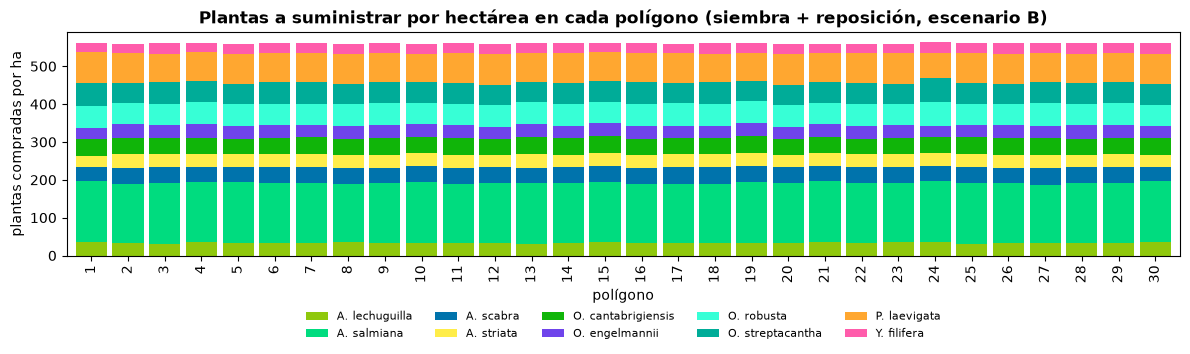

In [8]:
rep_usada = R.sum(2) / area                                                 # (N_SIM, E)
t3 = pd.DataFrame({'siembra_ha': QI.sum(1) / area,
                   'reposicion_comprada_ha': QR.sum(1) / area,
                   'reposicion_usada_ha_E': rep_usada.mean(0),
                   'reposicion_usada_P95': np.percentile(rep_usada, 95, axis=0)}, index=esp)
t3['suministrar_ha_E'] = t3.siembra_ha + t3.reposicion_usada_ha_E
t3['comprado_ha'] = t3.siembra_ha + t3.reposicion_comprada_ha
t3['costo_comprado_ha'] = c * t3.comprado_ha
t3['costo_suministrado_ha_E'] = c * t3.suministrar_ha_E
t3.loc['Total'] = t3.sum()
display(t3.round(2))
print(f"Por hectárea se compran {t3.loc['Total', 'comprado_ha']:.1f} plantas (${t3.loc['Total', 'costo_comprado_ha']:,.0f}) "
      f"y en promedio se usan {t3.loc['Total', 'suministrar_ha_E']:.1f} (${t3.loc['Total', 'costo_suministrado_ha_E']:,.0f}).")

pol3 = (q.assign(q_ha=q.q_total / q.area_ha).pivot(index='poligono', columns='especie', values='q_ha')[esp])
fig, ax = plt.subplots(figsize=(12, 4))
pol3.plot.bar(stacked=True, ax=ax, color=PALETA, width=0.85, legend=False)
ax.set_ylabel('plantas compradas por ha'); ax.set_xlabel('polígono')
ax.set_title(f'Plantas a suministrar por hectárea en cada polígono (siembra + reposición, escenario {ESC})', fontweight='bold')
ax.legend(corto, ncol=5, fontsize=8, frameon=False, loc='lower center', bbox_to_anchor=(0.5, -0.42))
plt.tight_layout(); plt.show()

## 4. Probabilidad de transición entre plantas

Cada planta es un estado (su especie, o "vacío"). La cuadrilla recorre la malla fila por fila, en zigzag: las filas impares de izquierda a derecha y las pares de regreso. Dentro de una fila del polígono la plantilla se repite cada 47 columnas, así que después de la columna 47 sigue la columna 1. La probabilidad de transición es

$$P_{ij} = \Pr(\text{la siguiente planta es de la especie } j \mid \text{la actual es de la especie } i) = \frac{n_{ij}}{\sum_k n_{ik}},$$

donde $n_{ij}$ cuenta cuántas veces, al recorrer la plantilla, una planta $i$ va seguida de una $j$. Los cambios de fila se ignoran porque son muy pocos frente a la longitud de las filas.

Como referencia se compara con un acomodo aleatorio con los mismos conteos, donde $P_{ij}\approx w_j/(658-1)$ (y $P_{ii}\approx(w_i-1)/657$). Además, la distribución estacionaria de la cadena debe coincidir con la proporción de cada especie en la plantilla, lo que sirve como comprobación.

In [9]:
def leer_plantilla(df):
    nf, nk = df.fila.max(), df.columna.max()
    M = df.pivot(index='fila', columns='columna', values='especie').loc[range(1, nf + 1), range(1, nk + 1)]
    return M.values

def transiciones(T, estados):
    # Cuenta i -> j en el recorrido en zigzag, con la fila repetida cada nk columnas.
    ix = {e: k for k, e in enumerate(estados)}; n = np.zeros((len(estados), len(estados)))
    for f, fila in enumerate(T):
        seq = fila if f % 2 == 0 else fila[::-1]                            # filas 1, 3, ... de ida; 2, 4, ... de regreso
        for a, b in zip(seq, np.r_[seq[1:], seq[:1]]):                      # cíclico: la columna 47 sigue con la 1
            n[ix[a], ix[b]] += 1
    return n

plantilla_plan = pd.read_csv(SALIDAS + 'plantilla_plan.csv')
T = leer_plantilla(plantilla_plan)
estados = [e for e in esp + ['vacio', 'vacío'] if e in set(T.ravel())]
n = transiciones(T, estados)
P = n / n.sum(1, keepdims=True)
etq = [corto[esp.index(e)] if e in esp else 'vacío' for e in estados]
P_df = pd.DataFrame(P, index=etq, columns=etq)
print(f'Plantilla del plan: {T.shape[0]} × {T.shape[1]} = {T.size} posiciones, {int(n.sum())} transiciones')
display(P_df.round(3))

Plantilla del plan: 14 × 47 = 658 posiciones, 658 transiciones


,A. lechuguilla,A. salmiana,A. scabra,A. striata,O. cantabrigiensis,O. engelmannii,O. robusta,O. streptacantha,P. laevigata,Y. filifera
A. lechuguilla,0.000,0.524,0.000,0.048,0.095,0.024,0.095,0.119,0.000,0.095
A. salmiana,0.117,0.281,0.087,0.077,0.041,0.031,0.087,0.046,0.199,0.036
A. scabra,0.000,0.429,0.000,0.071,0.286,0.048,0.167,0.000,0.000,0.000
A. striata,0.071,0.238,0.048,0.000,0.214,0.190,0.190,0.000,0.048,0.000
O. cantabrigiensis,0.041,0.184,0.224,0.224,0.000,0.102,0.163,0.020,0.041,0.000
O. engelmannii,0.026,0.316,0.079,0.026,0.158,0.026,0.289,0.053,0.026,0.000
O. robusta,0.068,0.274,0.123,0.123,0.082,0.178,0.041,0.014,0.082,0.014
O. streptacantha,0.047,0.188,0.000,0.000,0.000,0.000,0.016,0.312,0.406,0.031
P. laevigata,0.012,0.395,0.000,0.012,0.047,0.023,0.151,0.267,0.000,0.093
Y. filifera,0.154,0.154,0.000,0.000,0.000,0.000,0.038,0.115,0.385,0.154


,proporción en la plantilla,estacionaria de la cadena,P(repetir especie) plantilla,P(repetir especie) aleatorio
A. lechuguilla,0.0638,0.0638,0.0000,0.0624
A. salmiana,0.2979,0.2979,0.2806,0.2968
A. scabra,0.0638,0.0638,0.0000,0.0624
A. striata,0.0638,0.0638,0.0000,0.0624
O. cantabrigiensis,0.0745,0.0745,0.0000,0.0731
O. engelmannii,0.0578,0.0578,0.0263,0.0563
O. robusta,0.1109,0.1109,0.0411,0.1096
O. streptacantha,0.0973,0.0973,0.3125,0.0959
P. laevigata,0.1307,0.1307,0.0000,0.1294
Y. filifera,0.0395,0.0395,0.1538,0.0381


Máxima diferencia entre la estacionaria y la proporción: 1.67e-16
Probabilidad de que dos plantas consecutivas sean de la misma especie: plantilla 0.126, aleatorio 0.149


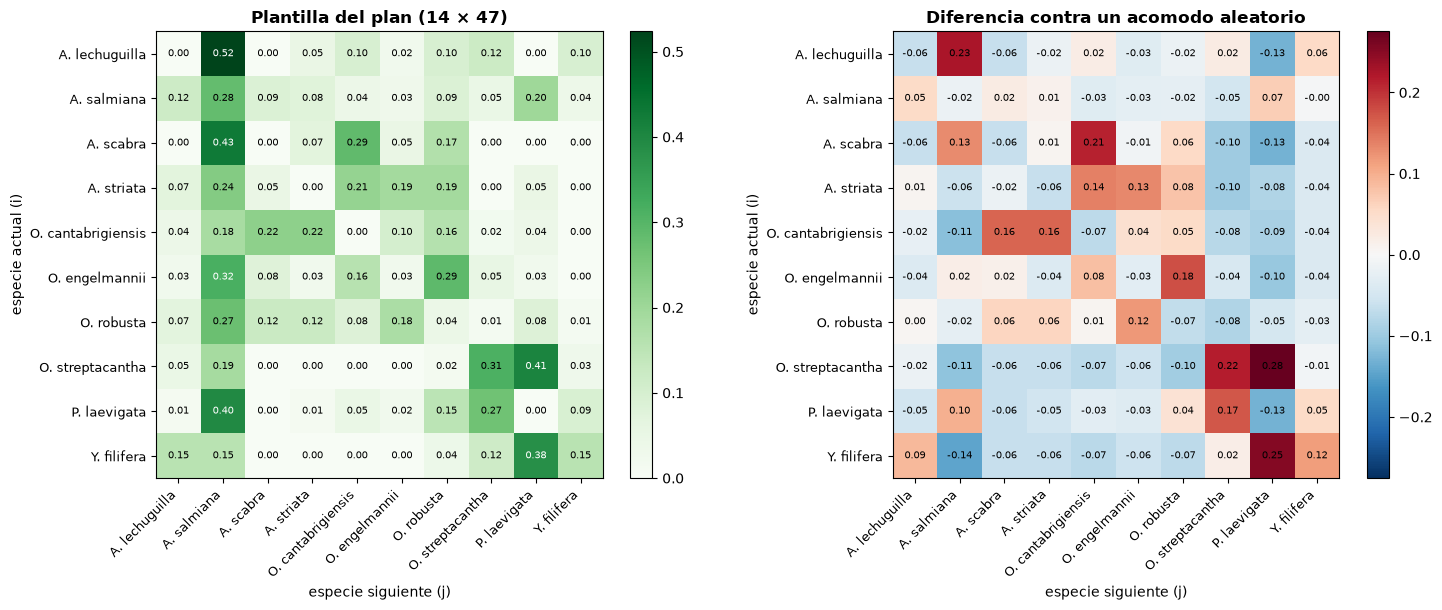

In [10]:
# Comprobaciones: filas suman 1 y la distribución estacionaria coincide con la proporción de cada especie
w = np.array([(T == e).sum() for e in estados], float)
vals, vecs = np.linalg.eig(P.T); pi = np.real(vecs[:, np.argmin(np.abs(vals - 1))]); pi /= pi.sum()
assert np.allclose(P.sum(1), 1)
P_aleat = (np.tile(w, (len(w), 1)) - np.eye(len(w))) / (w.sum() - 1)        # acomodo aleatorio con los mismos conteos
chk = pd.DataFrame({'proporción en la plantilla': w / w.sum(), 'estacionaria de la cadena': pi,
                    'P(repetir especie) plantilla': np.diag(P), 'P(repetir especie) aleatorio': np.diag(P_aleat)}, index=etq)
display(chk.round(4))
print(f'Máxima diferencia entre la estacionaria y la proporción: {np.abs(pi - w / w.sum()).max():.2e}')
print(f'Probabilidad de que dos plantas consecutivas sean de la misma especie: plantilla {np.sum(w / w.sum() * np.diag(P)):.3f}, '
      f'aleatorio {np.sum(w / w.sum() * np.diag(P_aleat)):.3f}')

fig, axs = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, M, tit in ((axs[0], P, 'Plantilla del plan (14 × 47)'), (axs[1], P - P_aleat, 'Diferencia contra un acomodo aleatorio')):
    lim = np.abs(M).max()
    im = ax.imshow(M, cmap='Greens' if ax is axs[0] else 'RdBu_r', vmin=0 if ax is axs[0] else -lim, vmax=lim)
    ax.set_xticks(range(len(etq)), etq, rotation=45, ha='right', fontsize=9); ax.set_yticks(range(len(etq)), etq, fontsize=9)
    for a in range(len(etq)):
        for b in range(len(etq)):
            ax.text(b, a, f'{M[a, b]:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if (ax is axs[0] and M[a, b] > 0.6 * lim) else 'black')
    ax.set_xlabel('especie siguiente (j)'); ax.set_ylabel('especie actual (i)'); ax.set_title(tit, fontweight='bold')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.savefig(SALIDAS + 'matriz_transicion.png', dpi=200, bbox_inches='tight'); plt.show()

**Transiciones con las plantillas de cada polígono.** Si se usa una plantilla por polígono, cada una tiene su propia matriz. Aquí se resume qué tanto se parecen: la matriz promedio de los 30 polígonos y la mayor diferencia de cada entrada contra la del plan.

In [11]:
pp = pd.read_csv(SALIDAS + 'plantillas_poligono.csv')
Ps = []
for p_, g_ in pp.groupby('poligono'):
    Tp = leer_plantilla(g_); np_ = transiciones(Tp, estados)
    with np.errstate(invalid='ignore', divide='ignore'):
        Ps.append(np.where(np_.sum(1, keepdims=True) > 0, np_ / np_.sum(1, keepdims=True), np.nan))
Ps = np.array(Ps)
P_prom = pd.DataFrame(np.nanmean(Ps, 0), index=etq, columns=etq)
print(f'{len(Ps)} plantillas de polígono | mayor diferencia entre la matriz promedio y la del plan: '
      f'{np.nanmax(np.abs(P_prom.values - P)):.3f}')
P_df.to_csv(SALIDAS + 'matriz_transicion_plan.csv'); P_prom.to_csv(SALIDAS + 'matriz_transicion_promedio_poligonos.csv')
for nombre, t in (('existentes_total_ha', t1), ('existentes_especie_ha', t2), ('suministrar_especie_ha', t3)):
    t.to_csv(SALIDAS + f'entregable_{nombre}.csv')
print('Guardados en salidas/: entregable_*.csv, matriz_transicion_plan.csv, matriz_transicion_promedio_poligonos.csv, matriz_transicion.png')
P_prom.round(3)

30 plantillas de polígono | mayor diferencia entre la matriz promedio y la del plan: 0.177
Guardados en salidas/: entregable_*.csv, matriz_transicion_plan.csv, matriz_transicion_promedio_poligonos.csv, matriz_transicion.png


,A. lechuguilla,A. salmiana,A. scabra,A. striata,O. cantabrigiensis,O. engelmannii,O. robusta,O. streptacantha,P. laevigata,Y. filifera
A. lechuguilla,0.000,0.549,0.035,0.018,0.051,0.043,0.128,0.098,0.003,0.074
A. salmiana,0.113,0.342,0.074,0.073,0.038,0.027,0.055,0.060,0.193,0.025
A. scabra,0.034,0.317,0.000,0.069,0.162,0.134,0.228,0.001,0.054,0.001
A. striata,0.031,0.333,0.075,0.000,0.171,0.122,0.225,0.003,0.038,0.001
O. cantabrigiensis,0.042,0.145,0.140,0.131,0.001,0.181,0.280,0.009,0.070,0.003
O. engelmannii,0.050,0.139,0.154,0.149,0.235,0.000,0.183,0.011,0.072,0.007
O. robusta,0.066,0.146,0.154,0.137,0.201,0.120,0.004,0.031,0.123,0.017
O. streptacantha,0.063,0.187,0.002,0.001,0.007,0.012,0.032,0.255,0.373,0.070
P. laevigata,0.004,0.383,0.021,0.014,0.040,0.031,0.098,0.292,0.001,0.115
Y. filifera,0.097,0.185,0.001,0.000,0.002,0.011,0.047,0.147,0.397,0.113


## Lectura de los resultados

**1. Plantas existentes.** En el predio hay en promedio **122.4 plantas existentes por hectárea** (el valor exacto, $0.95\,x$, es 122.3, lo que confirma la simulación). Varía poco entre polígonos, de 116 a 132 por hectárea. A los dos años, con la siembra y la reposición del escenario B, se esperan **604.8 plantas vivas por hectárea**, el 91.9 % de la meta de 658. Como el total del predio suma 183 ha, la variación entre simulaciones es pequeña (P5–P95 de 604 a 606).

**2. Existentes por especie.** Las plantas existentes cubren entre 17 % y 20 % de la meta de **todas** las especies, es decir, ya están casi en la proporción del plan. Por eso una plantilla con la proporción de la meta no se aleja mucho de lo que hace falta sembrar: lo que la separa de la compra optimizada es la diferencia en supervivencia entre especies. A los dos años todas las especies quedan cerca de 92 % de su meta, que es el efecto del criterio equilibrado.

**3. Plantas a suministrar.** Por hectárea se compran **560.5 plantas** (535.6 de siembra y 24.9 de reposición), con un costo de \$13,200. Las especies con menor supervivencia reciben más reposición por planta sembrada: *A. scabra* (5.3 por ha, 14 % de su siembra) y *Y. filifera* (4.0 por ha, 18 %). En la simulación se usan prácticamente todas las reposiciones compradas (24.85 de 24.87 por ha): mueren unas 70 plantas por hectárea y solo se compraron 25 para reponer, así que el presupuesto de reposición siempre se agota.

**4. Transiciones.** La cadena reproduce exactamente la proporción de cada especie (la distribución estacionaria coincide con la plantilla), y la probabilidad de que dos plantas consecutivas sean de la misma especie es 0.126, contra 0.149 de un acomodo aleatorio. Lo más claro es que **nunca va un mezquite después de otro mezquite** ($P=0$, porque su competencia consigo mismo es 10) ni se repiten los agaves pequeños y *O. cantabrigiensis*. En cambio, *O. streptacantha* sí se repite (0.31), porque su competencia consigo misma es casi igual a la que tiene con las demás especies. Después de un mezquite casi siempre sigue *A. salmiana* (0.40) u *O. streptacantha* (0.27), y después de una yuca, un mezquite (0.39). Las plantillas de cada polígono tienen matrices parecidas a la del plan (diferencia máxima de 0.18 en una entrada), así que estas reglas sirven para todo el predio.

## 5. Competencia esperada por hectárea

La plantilla de 14 × 47 equivale a una hectárea (658 puntos). Se usa la misma malla que en v6: tres bolillo, 6 vecinas por punto, bordes periódicos, es decir, 3 × 658 = 1,974 pares de vecinas. La plantilla es `plantilla_plan.csv`, que ya incluye el castigo por agrupamiento de 5.4, y la matriz $C_{ij}$ es `Competencia.xlsx`.

Cada punto $k$ tiene una especie planeada $s_k$ y, a los dos años, puede estar en uno de tres estados:

- **Existente**, con probabilidad $\rho=\mathbb{E}[X]/658$. Como no se sabe dónde están ni de qué especie son, su especie sigue la composición del inventario, $\hat\pi^X_e=\mathbb{E}[X_e]/\mathbb{E}[X]$.
- **Planta nueva viva** de la especie planeada, con probabilidad $(1-\rho)\,a_{s_k}$, donde $a_e=S_e+(1-S_e)\,r_e\,S_e$ y $r_e$ es la fracción de las muertas que se repone (reposiciones usadas entre muertas esperadas, de la simulación de la sección 1).
- **Vacío**, con el resto de la probabilidad. Un punto vacío no compite.

El vector de probabilidades de cada punto es $\pi_k(e)=\rho\,\hat\pi^X_e+(1-\rho)\,a_{s_k}\mathbf 1[e=s_k]$. Si los puntos son independientes, la competencia esperada es exacta y no requiere simular:

$$\mathbb{E}[Z]=\sum_{(k,l)\ \text{vecinas}}\pi_k^\top C\,\pi_l .$$

Se separa en tres partes: **nueva–nueva** (la única que depende del acomodo), **nueva–existente** y **existente–existente** ($\rho^2\cdot1974\cdot\hat\pi^{X\top}C\hat\pi^X$, que no depende de la plantilla). Después, 1,000 simulaciones a nivel de punto validan la fórmula y dan percentiles 5–95. Cada etapa se compara con un acomodo aleatorio de las mismas especies (1,000 permutaciones de la plantilla).

**Etapas que se reportan:** (1) $Z$ de diseño, con todas las plantas vivas y sin existentes; (2) justo después de sembrar, con existentes y todas las nuevas vivas; (3) esperada a los dos años, con supervivencia y reposición.

**Supuestos.** La especie y la ubicación de las existentes son aleatorias; si algún día se conoce su ubicación, esa parte se calcula exacta. $C_{ij}$ es igual para plantas nuevas y establecidas, y una planta muerta deja de competir. $r_e$ viene de la reposición comprada del plan, y la plantilla se evalúa como si cada especie se sembrara en su proporción. La hectárea tiene bordes periódicos (hectárea interior); en la orilla de un polígono hay menos vecinas y la competencia por hectárea es algo menor. $\rho$ varía entre polígonos (17 % a 21 %); aquí se usa el promedio del predio.

In [12]:
# ---------- 5.1 Insumos: matriz C, malla de tres bolillo y probabilidades por punto ----------
ARCH_C = DATOS + 'Competencia.xlsx'
if not os.path.exists(ARCH_C):
    raise FileNotFoundError(f'Falta {ARCH_C}: sin la C real la competencia esperada no es válida '
                            '(v6 usa una matriz de ejemplo cuando no existe).')
C = pd.read_excel(ARCH_C, index_col=0).loc[esp, esp].values.astype(float)
assert np.allclose(C, C.T)

NF, NK = T.shape; NN = T.size
assert (NF, NK) == (14, 47), 'la plantilla debe ser de 14 × 47'
idx = {e: i for i, e in enumerate(esp)}
assert set(T.ravel()) <= set(esp), 'la plantilla tiene estados que no son especies (¿vacíos?)'
s = np.array([idx[e] for e in T.ravel()])                      # especie planeada de cada punto (fila por fila, como en v6)

# Malla de tres bolillo con bordes periódicos: misma definición que v6
def vecinos(r, k):
    if r % 2 == 1: v = [(r, k-1), (r, k+1), (r-1, k-1), (r-1, k), (r+1, k-1), (r+1, k)]
    else:          v = [(r, k-1), (r, k+1), (r-1, k),   (r-1, k+1), (r+1, k), (r+1, k+1)]
    return [(((a-1) % NF) + 1, ((b-1) % NK) + 1) for a, b in v]

pos = [(r, k) for r in range(1, NF + 1) for k in range(1, NK + 1)]
ix  = {q: i for i, q in enumerate(pos)}
NB  = np.array([[ix[v] for v in vecinos(r, k)] for r, k in pos])
ARISTAS = np.array(sorted({tuple(sorted((i, j))) for i in range(NN) for j in NB[i]}))
assert len(ARISTAS) == 3 * NN == 1974
K, L = ARISTAS[:, 0], ARISTAS[:, 1]                            # extremos de cada par de vecinas

# Probabilidades del modelo
EXe  = 0.95 * x.values.sum(1) / area                           # E[X_e] por ha (exacto)
rho  = EXe.sum() / NN                                          # prob. de que un punto tenga una existente
piX  = EXe / EXe.sum()                                         # composición de las existentes
muertas_ha = (QI * (1 - S[:, None])).sum(1) / area             # muertas esperadas por ha y especie
r_e  = np.clip(rep_usada.mean(0) / muertas_ha, 0, 1)           # fracción de muertas que se repone
a    = S + (1 - S) * r_e * S                                   # prob. de que el punto termine con planta nueva viva
print(f'rho = {rho:.4f} | pares de vecinas = {len(K):,} | {C_FUENTE if "C_FUENTE" in globals() else "Competencia.xlsx"}')
display(pd.DataFrame({'S_e': S, 'r_e (fracción repuesta)': r_e, 'a_e': a, 'pi_X': piX}, index=corto).round(3))

rho = 0.1859 | pares de vecinas = 1,974 | Competencia.xlsx


,S_e,r_e (fracción repuesta),a_e,pi_X
A. lechuguilla,0.926,0.362,0.951,0.063
A. salmiana,0.908,0.299,0.933,0.295
A. scabra,0.745,0.567,0.853,0.062
A. striata,0.914,0.328,0.940,0.060
O. cantabrigiensis,0.829,0.250,0.864,0.078
O. engelmannii,0.819,0.269,0.859,0.062
O. robusta,0.920,0.340,0.945,0.117
O. streptacantha,0.852,0.210,0.879,0.097
P. laevigata,0.818,0.231,0.852,0.128
Y. filifera,0.726,0.641,0.854,0.039


In [13]:
# ---------- 5.2 Competencia esperada exacta y su descomposición ----------
def Ez_partes(sv, a_, rho_):
    An, sK, sL = a_[sv], sv[K], sv[L]
    nn = ((1 - rho_) ** 2 * An[K] * An[L] * C[sK, sL]).sum()                                   # nueva–nueva
    ne = ((1 - rho_) * rho_ * (An[K] * (C @ piX)[sK] + (piX @ C)[sL] * An[L])).sum()           # nueva–existente
    ee = rho_ ** 2 * len(K) * (piX @ C @ piX)                                                  # existente–existente
    return pd.Series({'nueva-nueva': nn, 'nueva-existente': ne, 'existente-existente': ee, 'total': nn + ne + ee})

# Comprobación: la descomposición coincide con el cálculo directo sum_(k,l) pi_k' C pi_l
Pi = rho * piX[None, :] + (1 - rho) * a[s][:, None] * np.eye(E_)[s]
assert np.isclose(np.einsum('pe,ef,pf->', Pi[K], C, Pi[L]), Ez_partes(s, a, rho)['total'])

# Acomodo aleatorio: mismas especies, 1,000 permutaciones de la plantilla
g_perm = np.random.default_rng(SEED + 1)
perms  = [g_perm.permutation(s) for _ in range(N_SIM)]
def Ez_aleatorio(a_, rho_):
    return pd.DataFrame([Ez_partes(p_, a_, rho_) for p_ in perms]).mean()

etapas = {'1. Z de diseño':           dict(rho=0.0, a=np.ones(E_)),
          '2. Después de sembrar':    dict(rho=rho, a=np.ones(E_), Sv=np.ones(E_), rv=np.zeros(E_)),
          '3. Esperada a 2 años':     dict(rho=rho, a=a,           Sv=S,           rv=r_e)}
partes = {nom: (Ez_partes(s, cfg['a'], cfg['rho']), Ez_aleatorio(cfg['a'], cfg['rho'])) for nom, cfg in etapas.items()}
print('Z de diseño (plantilla del plan):', round(partes['1. Z de diseño'][0]['total'], 1))

Z de diseño (plantilla del plan): 4851.0


In [14]:
# ---------- 5.3 Simulación a nivel de punto (validación e intervalos) ----------
Cp = np.zeros((E_ + 1, E_ + 1)); Cp[:E_, :E_] = C              # el índice E_ es "vacío" y no compite

def simular_Z(sv, rho_, Sv, rv, n=N_SIM, seed=SEED):
    g = np.random.default_rng(seed); N = len(sv)
    hay_ex = g.random((n, N)) < rho_                            # puntos con planta existente
    sp_ex  = g.choice(E_, size=(n, N), p=piX)                   # especie de la existente
    viva   = g.random((n, N)) < Sv[sv]                          # sobrevive la planta nueva
    repone = (~viva) & (g.random((n, N)) < rv[sv]) & (g.random((n, N)) < Sv[sv])   # se repone y la reposición sobrevive
    est = np.where(viva | repone, sv, E_)                       # estado del punto: especie o vacío
    est = np.where(hay_ex, sp_ex, est)
    return Cp[est[:, K], est[:, L]].sum(1)                      # Z de cada corrida

sim = {nom: simular_Z(s, cfg['rho'], cfg['Sv'], cfg['rv']) for nom, cfg in list(etapas.items())[1:]}

,Z plantilla (exacta),Z acomodo aleatorio,reducción vs aleatorio %,Z simulada (media),P5,P95
etapa,,,,,,
1. Z de diseño,4851.0,6267.8,22.6,NaN,NaN,NaN
2. Después de sembrar,5328.7,6267.7,15.0,5338.0,5173.1,5521.3
3. Esperada a 2 años,4514.2,5266.1,14.3,4517.8,4286.9,4761.8


2. Después de sembrar: fórmula 5328.7 vs simulación 5338.0 (diferencia +0.17 %)
3. Esperada a 2 años: fórmula 4514.2 vs simulación 4517.8 (diferencia +0.08 %)


,1. plantilla,1. aleatorio,2. plantilla,2. aleatorio,3. plantilla,3. aleatorio
nueva-nueva,4851.0,6267.8,3214.7,4153.7,2594.6,3346.5
nueva-existente,0.0,0.0,1897.6,1897.6,1703.2,1703.2
existente-existente,0.0,0.0,216.4,216.4,216.4,216.4
total,4851.0,6267.8,5328.7,6267.7,4514.2,5266.1


Etapa 3, plantilla: nueva-nueva 57.5 % | nueva-existente 37.7 % | existente-existente 4.8 %


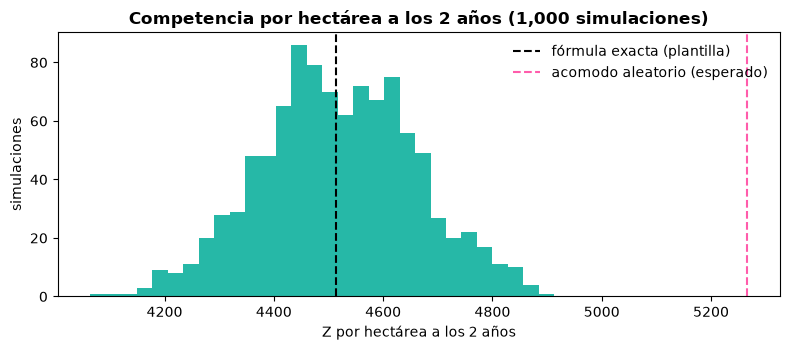

In [15]:
# ---------- 5.4 Resultados por hectárea ----------
filas = []
for nom, (pl, al) in partes.items():
    fila = {'etapa': nom, 'Z plantilla (exacta)': pl['total'], 'Z acomodo aleatorio': al['total'],
            'reducción vs aleatorio %': 100 * (1 - pl['total'] / al['total'])}
    if nom in sim:
        z = sim[nom]; fila.update({'Z simulada (media)': z.mean(), 'P5': np.percentile(z, 5), 'P95': np.percentile(z, 95)})
    filas.append(fila)
t5 = pd.DataFrame(filas).set_index('etapa')
display(t5.round(1))
for nom, z in sim.items():
    print(f'{nom}: fórmula {partes[nom][0]["total"]:.1f} vs simulación {z.mean():.1f} '
          f'(diferencia {100 * (z.mean() / partes[nom][0]["total"] - 1):+.2f} %)')

# Qué parte de Z se puede reducir con el acomodo
t5p = pd.DataFrame({f'{nom[0]}. {tipo}': ser for nom, (pl, al) in partes.items()
                    for tipo, ser in (('plantilla', pl), ('aleatorio', al))})
display(t5p.round(1))
z3 = partes['3. Esperada a 2 años'][0]
print('Etapa 3, plantilla: ' + ' | '.join(f'{k} {100 * z3[k] / z3["total"]:.1f} %' for k in z3.index[:3]))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(sim['3. Esperada a 2 años'], bins=30, color='#00ac98', alpha=0.85)
ax.axvline(z3['total'], color='k', ls='--', label='fórmula exacta (plantilla)')
ax.axvline(partes['3. Esperada a 2 años'][1]['total'], color='#ff5cab', ls='--', label='acomodo aleatorio (esperado)')
ax.set_xlabel('Z por hectárea a los 2 años'); ax.set_ylabel('simulaciones'); ax.legend(frameon=False)
ax.set_title('Competencia por hectárea a los 2 años (1,000 simulaciones)', fontweight='bold'); plt.tight_layout(); plt.show()

t5.to_csv(SALIDAS + 'entregable_competencia_esperada_ha.csv'); t5p.to_csv(SALIDAS + 'entregable_competencia_partes_ha.csv')